In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
dataset = pd.read_csv("Position_Salaries.csv")
X = dataset.iloc[:,1:-1].values
y = dataset.iloc[:,-1].values.reshape(10,1)

In [3]:
from sklearn.ensemble import RandomForestRegressor
RFR = RandomForestRegressor()
RFR.fit(X,y)

C:\Users\Raj\AppData\Roaming\Python\Python314\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [4]:
RFR.predict([[6.5]])

array([157600.])

# Random Forest Regression - Complete Working (Training to Prediction)

Random Forest Regression is an **ensemble learning algorithm** that combines the predictions of **multiple Decision Trees** instead of relying on a single Decision Tree. Since each tree is trained on a different version of the dataset, their predictions are slightly different. The final prediction is obtained by taking the **average of all Decision Tree predictions**, making Random Forest more accurate and less likely to overfit than a single Decision Tree.

---

# Dataset

Suppose we have the following dataset:

| Level | Salary |
|------:|--------:|
|1|45000|
|2|50000|
|3|60000|
|4|80000|
|5|110000|
|6|150000|
|7|200000|
|8|300000|
|9|500000|
|10|1000000|

Our goal is to predict the salary based on the employee's level.

---

# Step 1: Import the Model

```python
from sklearn.ensemble import RandomForestRegressor
```

This imports the `RandomForestRegressor` class from Scikit-Learn.

At this stage:

- No Decision Trees are created.
- No training has started.
- The model is empty.

---

# Step 2: Create the Random Forest Model

```python
RF = RandomForestRegressor(
    n_estimators=5,
    random_state=0
)
```

Here,

- `n_estimators=5` means Random Forest should create **5 Decision Trees**.
- `random_state=0` fixes the random process so that the same trees are created every time the program runs.

At this point, the model has not learned anything.

```
Random Forest

↓

No Decision Trees

↓

Waiting for fit()
```

---

# Step 3: Start Training

```python
RF.fit(X, y)
```

Calling `fit(X, y)` starts the learning process.

Random Forest first reads

```python
n_estimators = 5
```

and understands

> **"I have to create 5 Decision Trees."**

However, before creating a Decision Tree, it first needs a training dataset for that tree.

---

# Step 4: Create Bootstrap Sample for Tree 1

Random Forest does **not** directly give the original dataset to Tree 1.

Instead, it creates a **new training dataset** called a **Bootstrap Sample**.

Initially,

```
Tree 1 Dataset

↓

Empty
```

The original dataset acts as the source.

Random Forest repeatedly performs these steps:

1. Randomly select **one complete row** from the original dataset.
2. Copy that row into Tree 1's dataset.
3. Put the selected row back into the original dataset (**sampling with replacement**).
4. Repeat until Tree 1's dataset contains the required number of rows.

Since sampling is done **with replacement**:

- Some rows may appear multiple times.
- Some rows may never appear.

For example,

Suppose the completed Bootstrap Sample becomes

| Level | Salary |
|------:|--------:|
|6|150000|
|6|150000|
|9|500000|
|2|50000|
|4|80000|
|6|150000|
|10|1000000|
|8|300000|
|2|50000|
|5|110000|

Notice that:

- Level 6 appears three times.
- Level 2 appears twice.
- Levels 1, 3 and 7 are missing.

This is completely normal.

---

# Step 5: Train Decision Tree 1

Now Tree 1 uses **only its Bootstrap Sample** for training.

It works exactly like a normal Decision Tree Regression model.

The training process is:

1. The complete Bootstrap Sample becomes the Root Node.
2. Every possible split is checked.
3. The prediction error for every split is calculated.
4. The split with the minimum prediction error is selected.
5. Child Nodes are created.
6. The same process repeats recursively.
7. Training stops when the stopping conditions are satisfied.
8. Every Leaf Node stores the average target value (salary) of the samples present in that leaf.

Tree 1 is now completely trained.

---

# Step 6: Create and Train Remaining Trees

Random Forest again starts from the **original dataset**.

It creates another Bootstrap Sample for Tree 2.

Tree 2 is then trained exactly like a normal Decision Tree.

The same process repeats until all Decision Trees are trained.

For example,

```
Bootstrap Sample 1

↓

Train Tree 1

↓

Bootstrap Sample 2

↓

Train Tree 2

↓

Bootstrap Sample 3

↓

Train Tree 3

↓

Bootstrap Sample 4

↓

Train Tree 4

↓

Bootstrap Sample 5

↓

Train Tree 5
```

Since every tree receives a different Bootstrap Sample, every tree learns slightly differently.

---

# Step 7: Training is Complete

After `fit()` finishes, Random Forest stores all trained Decision Trees.

Each Decision Tree stores:

- Decision rules (split conditions)
- Internal nodes
- Leaf nodes
- Prediction value stored in every Leaf Node

The original training dataset is **not used during prediction**.

---

# Step 8: Model is Ready

After all Decision Trees are trained, Random Forest contains

```
Random Forest

├── Decision Tree 1
├── Decision Tree 2
├── Decision Tree 3
├── Decision Tree 4
└── Decision Tree 5
```

The model is now ready to predict new values.

---

# Step 9: Predict a New Salary

Now we write

```python
RF.predict([[6.5]])
```

We want to predict the salary for

```
Level = 6.5
```

Random Forest **does not make the prediction itself**.

Instead, it sends this input to **every Decision Tree**.

---

# Step 10: Tree 1 Predicts

Tree 1 receives

```
Level = 6.5
```

It starts at its **Root Node**.

Suppose the Root Node asks

```
Level < 5.5 ?
```

Since

```
6.5 > 5.5
```

Tree 1 moves to the **right child**.

The next decision is

```
Level < 8.5 ?
```

Since

```
6.5 < 8.5
```

Tree 1 moves to the **left child**.

It continues following its stored decision rules until it reaches a **Leaf Node**.

Suppose the Leaf Node stores

```
180000
```

Tree 1 predicts

```
180000
```

---

# Step 11: Tree 2 Predicts

Tree 2 also receives

```
Level = 6.5
```

Since Tree 2 was trained on a **different Bootstrap Sample**, its decision rules are different.

Suppose it predicts

```
210000
```

---

# Step 12: Remaining Trees Predict

Suppose the remaining trees predict

| Decision Tree | Prediction |
|--------------:|-----------:|
| Tree 3 | 190000 |
| Tree 4 | 205000 |
| Tree 5 | 195000 |

Now Random Forest has collected all predictions.

| Decision Tree | Prediction |
|--------------:|-----------:|
| Tree 1 | 180000 |
| Tree 2 | 210000 |
| Tree 3 | 190000 |
| Tree 4 | 205000 |
| Tree 5 | 195000 |

---

# Step 13: Calculate the Final Prediction

Since this is a **Regression** problem, Random Forest calculates the **average** of all Decision Tree predictions.

```
(180000 + 210000 + 190000 + 205000 + 195000)

÷ 5

= 196000
```

This average becomes the **final predicted salary**.

---

# Step 14: Return the Output

Finally,

```python
RF.predict([[6.5]])
```

returns

```python
array([196000.])
```

This means the predicted salary for

```
Level = 6.5
```

is

```
₹196000
```

---

# Complete Working Flow

```
Create Random Forest Model

↓

Call fit(X, y)

↓

Read n_estimators

↓

Create Bootstrap Sample for Tree 1

↓

Train Decision Tree 1

↓

Create Bootstrap Sample for Tree 2

↓

Train Decision Tree 2

↓

Repeat until all Decision Trees are trained

↓

Store all trained Decision Trees

↓

Model is Ready

↓

Call predict([[6.5]])

↓

Send input to every Decision Tree

↓

Each Decision Tree follows its stored decision rules

↓

Reach a Leaf Node

↓

Return the prediction stored in the Leaf Node

↓

Collect predictions from all Decision Trees

↓

Calculate the average of all predictions

↓

Return the Final Predicted Value
```

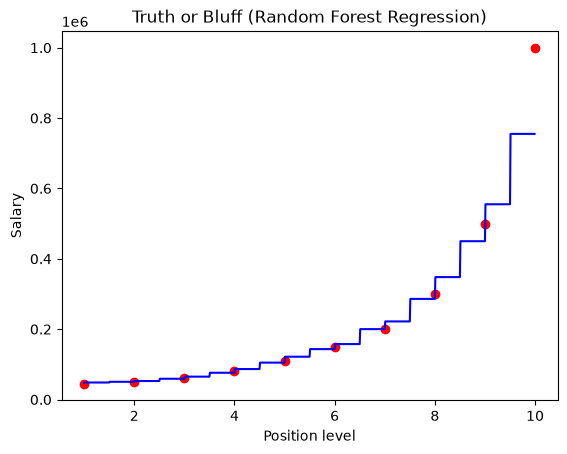

In [7]:

X_grid = np.arange(X.min(), X.max(), 0.01)
X_grid = X_grid.reshape((len(X_grid), 1))

plt.scatter(X, y, color='red')
plt.plot(X_grid, RFR.predict(X_grid), color='blue')

plt.title('Truth or Bluff (Random Forest Regression)')
plt.xlabel('Position level')
plt.ylabel('Salary')

plt.show()
